# Nastoyka: запуск бара, 60 л и экономика двух вечеров

Автор окончательно согласовал десять вкусов, составы, поставщиков, цены и план по 6 л (`author_selected_final`). План: по 60 порций каждого вкуса в пятницу и субботу, порция 50 мл. Это сценарий, а не подтверждённый спрос. Восемь основных по 250 ₽, две премиальные по 300 ₽. Исходные выходы автора оценочные; текущие статусы показаны в таблице. Деньги в представлении округлены до двух знаков, проценты до двух, количества до трёх; исходные CSV и расчёты не округляются. «Недоступно» означает отсутствие применимой цены или неприменимое поле; причина указана в статусах.

Предыдущие этапы исследования рынка и A/B/C/B2 сохранены [в истории](data/economics/history/README.md); текущий расчёт не импортирует старые дозировки и цены. [Отчёт](docs/economics_report.md) · [Авторское задание](docs/author_specification.md) · [Методика](docs/economics_methodology.md).

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import economics as e
ROOT = Path.cwd()
result = e.run()
inputs = e.load_inputs()
out = ROOT / "data/economics/results"
def read(name): return pd.read_csv(out/name)
def fig(name): display(Image(filename=str(ROOT/"figures/economics"/name)))
from scripts.report import notebook_table, fmt
def show(frame): display(notebook_table(frame))
print("Защищённых первичных файлов:", len(e.check_baseline()["protected_files_sha256"]))
show(pd.DataFrame([
    {"Показатель": label, "Значение, ₽": fmt(result[key])}
    for label,key in [("Первая закупка","purchase_cost_rub"),
                      ("Сырьё 60 л","used_cost_rub"),("Остаток сырья","leftover_value_rub"),
                      ("Выручка полной реализации","potential_revenue_rub"),
                      ("Доход после сырья","potential_material_contribution_rub")]
]))

Защищённых первичных файлов: 14


Показатель,"Значение, ₽"
Первая закупка,"40 002,80"
Сырьё 60 л,"36 357,61"
Остаток сырья,"3 645,19"
Выручка полной реализации,"312 000,00"
Доход после сырья,"275 642,39"


## 1. Ассортимент и происхождение данных

Предшествующая база: 43 карточки заведений, текущий срез 30. Из 368 отзывов проверены 358; из 468 упоминаний подтверждены 198 конкретных, из 108 отзывов, 114 вкусов. Нормализация сохраняет исходное имя, объединяет явные синонимы и разделяет разные сочетания ингредиентов. Хреновуха и щавель: по семь упоминаний и пять положительных; у томатной шесть положительных из одного заведения, в строгом срезе одно. [Результаты сбора](docs/collection_report.md) · [Методика](docs/methodology.md) · [Вкусовые базы](data/processed/flavor_summary.csv). Целью изучения баров и рюмочных Петербурга было найти ассортиментные сигналы и причины конкретных оценок. Связь заведение → отзыв → упоминание сохраняет независимую базу: несколько вкусов из одного отзыва не превращаются в нескольких гостей. Явные синонимы нормализованы, составные вкусы сохранены отдельно; общая оценка заведения не перенесена на напитки. Публичные отзывы не равны продажам и не представляют всех гостей. Варианты A/B/C/B2 были промежуточными; десять вкусов и разделение 8+2 автор выбрал самостоятельно, а не на основании доказанного оптимума. Клюква сохранена прямым решением автора. Новые отзывы не собирались.

Текущие источники: ассортимент CSV, recipes.json, yields.csv, ingredients.csv и production_plan.json. Все составы author_supplied, а не прежние адаптации. Цены предоставлены автором; часть имеет только индексные каталожные ориентиры, не подтверждение магазина СПб.

In [2]:
show(pd.DataFrame(inputs[0]))
show(pd.DataFrame(inputs[2].values()))
show(pd.DataFrame(inputs[3].values())[["ingredient_id","name","supplier","pack_price_rub","pack_size_base","base_unit","price_source_type","confirmation_status","reference_url"]])

candidate_id,normalized_flavor,tier,price_50ml_rub,selection_status
C01,Хреновуха,basic,"250,00",author_selected_final
C02,Вишня,basic,"250,00",author_selected_final
C03,Малина,basic,"250,00",author_selected_final
C04,Лимончелло,basic,"250,00",author_selected_final
C05,Щавель,basic,"250,00",author_selected_final
C09,Яблоко — базилик,basic,"250,00",author_selected_final
C13,Облепиха,basic,"250,00",author_selected_final
C14,Клюква,basic,"250,00",author_selected_final
C06,Халва,premium,"300,00",author_selected_final
C12,Малина — сливки,premium,"300,00",author_selected_final


candidate_id,yield_ml,yield_status,source_ref,measurement_note
C01,470,estimated,docs/author_specification.md,
C02,690,estimated,docs/author_specification.md,
C03,680,estimated,docs/author_specification.md,
C04,1 500,estimated,docs/author_specification.md,
C05,530,estimated,docs/author_specification.md,
C06,450,estimated,docs/author_specification.md,
C09,650,estimated,docs/author_specification.md,
C12,700,estimated,docs/author_specification.md,
C13,720,estimated,docs/author_specification.md,
C14,670,estimated,docs/author_specification.md,


ingredient_id,name,supplier,pack_price_rub,pack_size_base,base_unit,price_source_type,confirmation_status,reference_url
vodka,Водка Царская Оригинальная 40%,Ладога,"380,00",1 000,ml,author_direct_quote,author_scenario_only,
cherry,Вишня замороженная без косточек,METRO,"799,00",1 000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirmation,https://online.metro-cc.ru/products/metro-chef-vishnya-bez-kostochki-zamorozhennaya-1kg
raspberry,Малина замороженная,METRO,"999,00",1 000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirmation,https://online.metro-cc.ru/products/metro-chef-malina-zamorozhennaya-1kg
sea_buckthorn,Облепиха замороженная,METRO,"399,00",1 000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirmation,https://online.metro-cc.ru/products/oblepiha-1kg
cranberry,Клюква замороженная,METRO,"519,00",1 000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirmation,https://online.metro-cc.ru/products/klyukva-sadovaya-1kg
lemon,Лимоны целые,METRO,"179,00",1 000,g,author_catalog_scenario,author_scenario_only,
sorrel,Щавель свежий,METRO,"139,00",100,g,author_catalog_scenario,author_scenario_only,
basil,Базилик зелёный свежий,METRO,"149,00",50,g,author_catalog_scenario,author_scenario_only,
sugar,Сахар,METRO,"72,90",1 000,g,author_catalog_scenario,author_scenario_only,
honey,Мёд,METRO,"329,00",1 000,g,author_catalog_scenario,author_scenario_only,


## 2. Производственный план и технологии

Каждому вкусу нужно 6000 мл. Коэффициент 6000 / выход исходной партии не округляется; исходные рецепты не округляются до целых партий. Выход уже включает фильтрацию. 40% — крепость водки, не готовой настойки. Технологии ниже воспроизводят данные автора; отсутствующие длительности операций не придуманы.

In [3]:
for row in inputs[0]:
    cid = row["candidate_id"]
    recipe = inputs[1][cid]
    display(Markdown("**" + cid + " — " + row["normalized_flavor"] + "**"))
    show(pd.DataFrame([{"ingredient_id": key, "quantity": value, "unit": inputs[3][key]["base_unit"]} for key,value in recipe["ingredients"].items()]))
    display(Markdown("\n".join(str(i+1)+". "+s for i,s in enumerate(recipe["technology"]))))
print("C12: наблюдение автора 14 дней; подтверждённый безопасный срок хранения не установлен.")

**C01 — Хреновуха**

ingredient_id,quantity,unit
vodka,500,ml
horseradish,95,g
ginger,15,g
honey,10,g


1. Авторский технологический ориентир: настаивание 1 дн.
2. Получить процеженный напиток; длительность и отдельные операции фильтрации автором не нормированы.

**C02 — Вишня**

ingredient_id,quantity,unit
vodka,500,ml
cherry,250,g
sugar,250,g


...

1. Авторский технологический ориентир: настаивание 1 дн.
2. Получить процеженный напиток; длительность и отдельные операции фильтрации автором не нормированы.

**C12 — Малина — сливки**

ingredient_id,quantity,unit
vodka,300,ml
raspberry,300,g
cream,150,ml
milk,150,ml
sugar,100,g


1. Соединить малину и водку в стеклянной банке, закрыть и оставить на 7 дней в темноте при комнатной температуре, затем процедить.
2. Сливки 10%, молоко 3.2% и сахар нагревать при помешивании до растворения сахара, не доводя до кипения.
3. Остудить сливочную основу и смешать с процеженной малиновой основой.
4. Поместить в холодильник приблизительно на 2 дня. Перед подачей взболтать при расслоении.

C12: наблюдение автора 14 дней; подтверждённый безопасный срок хранения не установлен.


C04 использует весь сок и жёлтую цедру 1900 г целых лимонов; вода отсутствует. C09 — свежие зелёные яблоки 525 г. C06 имеет консервативный выход 450 мл. C12 — 7 дней малиновой основы, отдельная нагретая без кипения и остуженная молочная основа, затем около двух дней в холодильнике. Наблюдение автора о 14 днях не подтверждает безопасность коммерческого хранения.

## 3. Относительный календарь

Пятница D0, суббота D+1. Максимальный известный цикл 30 дней. Ромбы/звезда обозначают операции с неизвестной длительностью, а не нулевое время. Конкретная дата запуска не назначена.

candidate_id,flavor,phase,duration_days,duration_status,start_day_relative,end_day_relative,start_date,time_interpretation,ready_by_day_relative,launch_reference
C01,Хреновуха,infusion,1,author_specified,-1,0,недоступно,author_duration,0,Friday D0; Saturday D+1
C01,Хреновуха,filtration,недоступно,not_specified,0,0,недоступно,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
C02,Вишня,infusion,30,author_specified,-30,0,недоступно,author_duration,0,Friday D0; Saturday D+1
C02,Вишня,filtration,недоступно,not_specified,0,0,недоступно,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
C03,Малина,infusion,30,author_specified,-30,0,недоступно,author_duration,0,Friday D0; Saturday D+1
C03,Малина,filtration,недоступно,not_specified,0,0,недоступно,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
C04,Лимончелло,infusion,14,author_specified,-14,0,недоступно,author_duration,0,Friday D0; Saturday D+1
C04,Лимончелло,filtration,недоступно,not_specified,0,0,недоступно,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
C05,Щавель,infusion,16,author_specified,-16,0,недоступно,author_duration,0,Friday D0; Saturday D+1
C05,Щавель,filtration,недоступно,not_specified,0,0,недоступно,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1


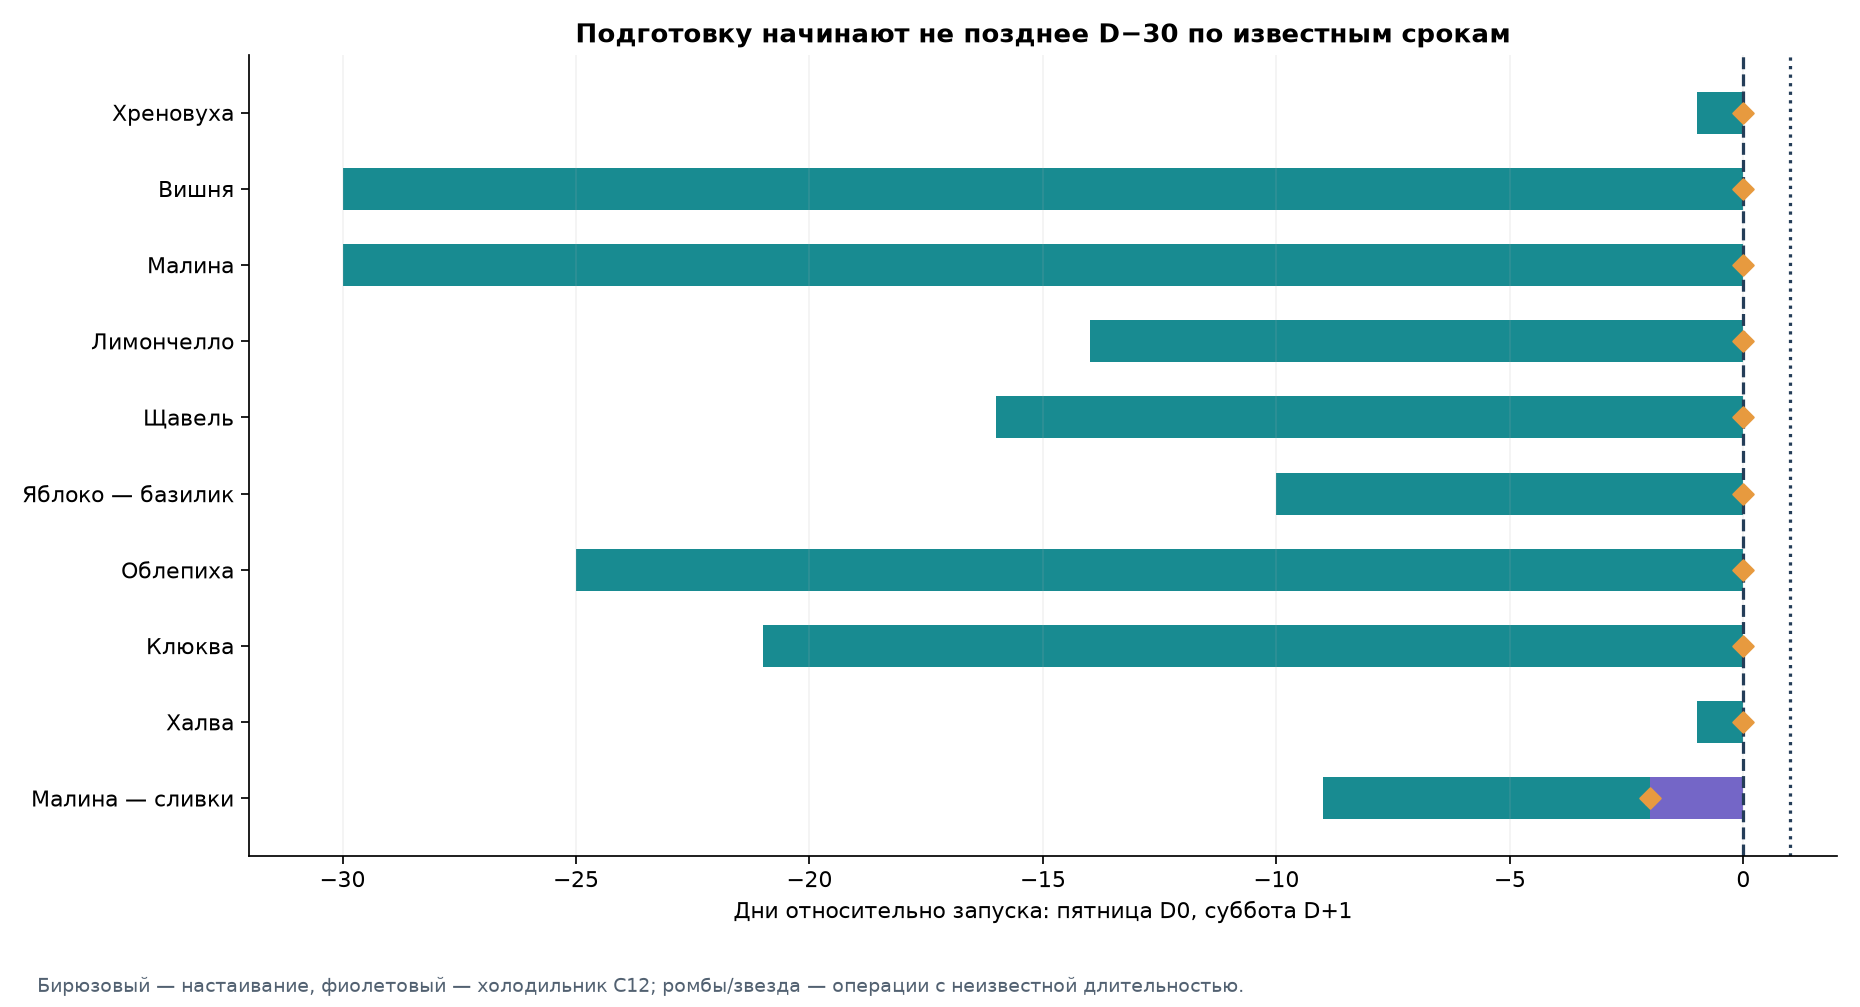

In [4]:
show(read("production_calendar.csv"))
fig("production_calendar.png")

## 4. Закупка целыми упаковками

Потребность общего ингредиента сначала суммируется по десяти вкусам. Только потом применяется округление упаковок вверх. Расход сырья, первый платёж и остаток различаются. Совместное округление и отдельные заказы сравниваются с учётом порога каждого заказа; при неизвестном тарифе экономия недоступна. В базовой закупке малины упаковочной экономии нет.

candidate_id,vodka,cherry,raspberry,sea_buckthorn,cranberry,lemon,sorrel,basil,sugar,honey,halva,cream,milk,horseradish,ginger,apple
C01,"6 382,979",0,0,0,0,0,0,0,0,"127,660",0,0,0,"1 212,766","191,489",0
C02,"4 347,826","2 173,913",0,0,0,0,0,0,"2 173,913",0,0,0,0,0,0,0
C03,"4 411,765",0,"2 647,059",0,0,0,0,0,"1 764,706",0,0,0,0,0,0,0
C04,4 000,0,0,0,0,7 600,0,0,2 000,0,0,0,0,0,0,0
C05,"5 660,377",0,0,0,0,0,"1 132,075",0,0,"1 132,075",0,0,0,0,0,0
C09,"4 615,385",0,0,0,0,0,0,"138,462","738,462",0,0,0,0,0,0,"4 846,154"
C13,"4 166,667",0,0,"4 166,667",0,0,0,0,"833,333",0,0,0,0,0,0,0
C14,"4 477,612",0,0,0,"3 582,090",0,0,0,"1 343,284",0,0,0,0,0,0,0
C06,"6 666,667",0,0,0,0,0,0,0,0,1 200,8 000,0,0,0,0,0
C12,"2 571,429",0,"2 571,429",0,0,0,0,0,"857,143",0,0,"1 285,714","1 285,714",0,0,0


ingredient_id,needed_quantity,base_unit,recipes_using,packs_to_buy,purchased_quantity,purchase_cost_rub,used_cost_rub,leftover_quantity,leftover_value_rub,joint_rounding_saving_rub
vodka,"47 300,705",ml,10,48,48 000,"18 240,00","17 974,27","699,295","265,73","1 520,00"
cherry,"2 173,913",g,1,3,3 000,"2 397,00","1 736,96","826,087","660,04","0,00"
raspberry,"5 218,487",g,2,6,6 000,"5 994,00","5 213,27","781,513","780,73","0,00"
sea_buckthorn,"4 166,667",g,1,5,5 000,"1 995,00","1 662,50","833,333","332,50","0,00"
cranberry,"3 582,090",g,1,4,4 000,"2 076,00","1 859,10","417,910","216,90","0,00"
lemon,7 600,g,1,8,8 000,"1 432,00","1 360,40",400,"71,60","0,00"
sorrel,"1 132,075",g,1,12,1 200,"1 668,00","1 573,58","67,925","94,42","0,00"
basil,"138,462",g,1,3,150,"447,00","412,62","11,538","34,38","0,00"
sugar,"9 710,840",g,7,10,10 000,"729,00","707,92","289,160","21,08","145,80"
honey,"2 459,735",g,3,3,3 000,"987,00","809,25","540,265","177,75","658,00"


supplier,purchase_cost_rub,used_cost_rub,leftover_value_rub,delivery_cost_rub,minimum_order_rub,terms_status
Ладога,"18 240,00","17 974,27","265,73",недоступно,недоступно,not_confirmed_for_author_scenario
METRO,"19 781,80","17 193,83","2 587,97",недоступно,недоступно,not_confirmed_for_author_scenario
Агропарк СПб,"1 981,00","1 189,51","791,49",недоступно,недоступно,not_confirmed_for_author_scenario


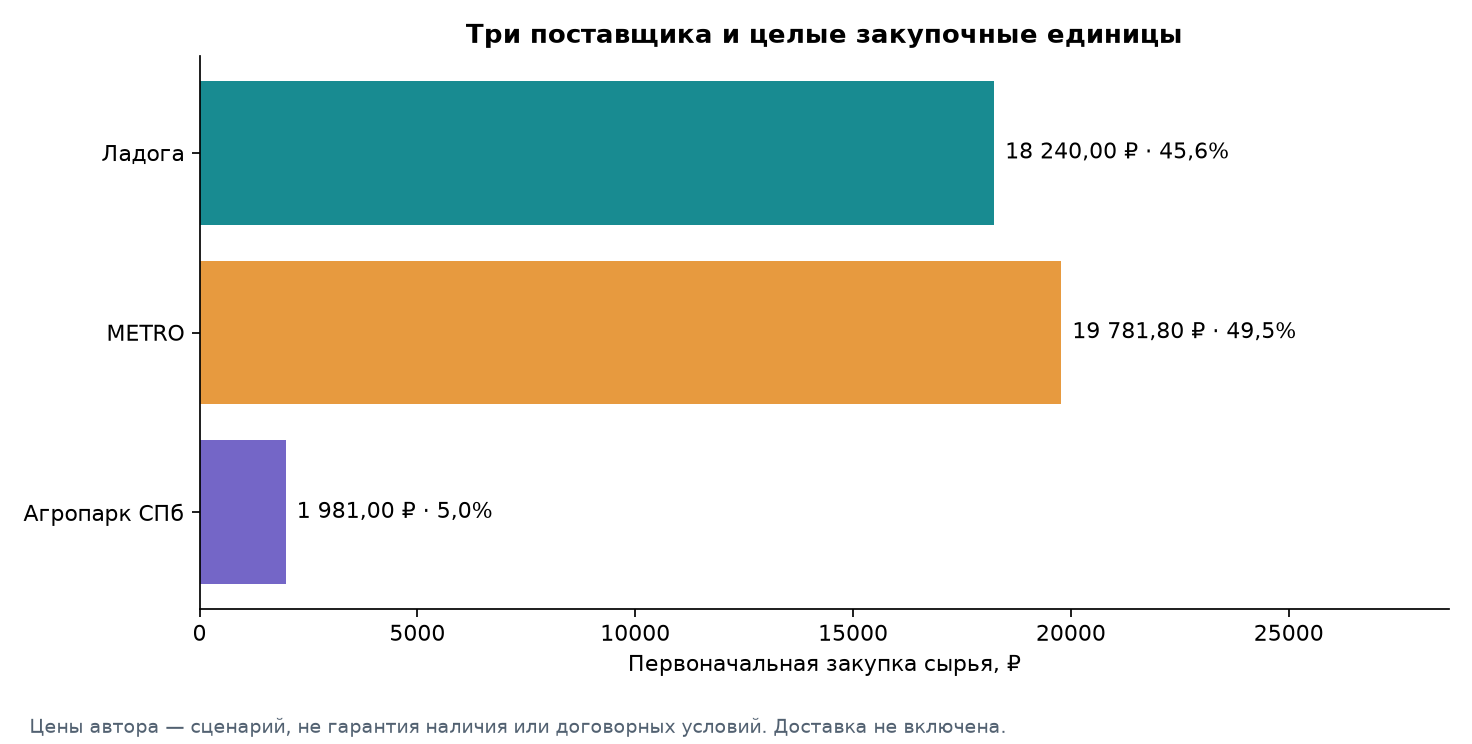

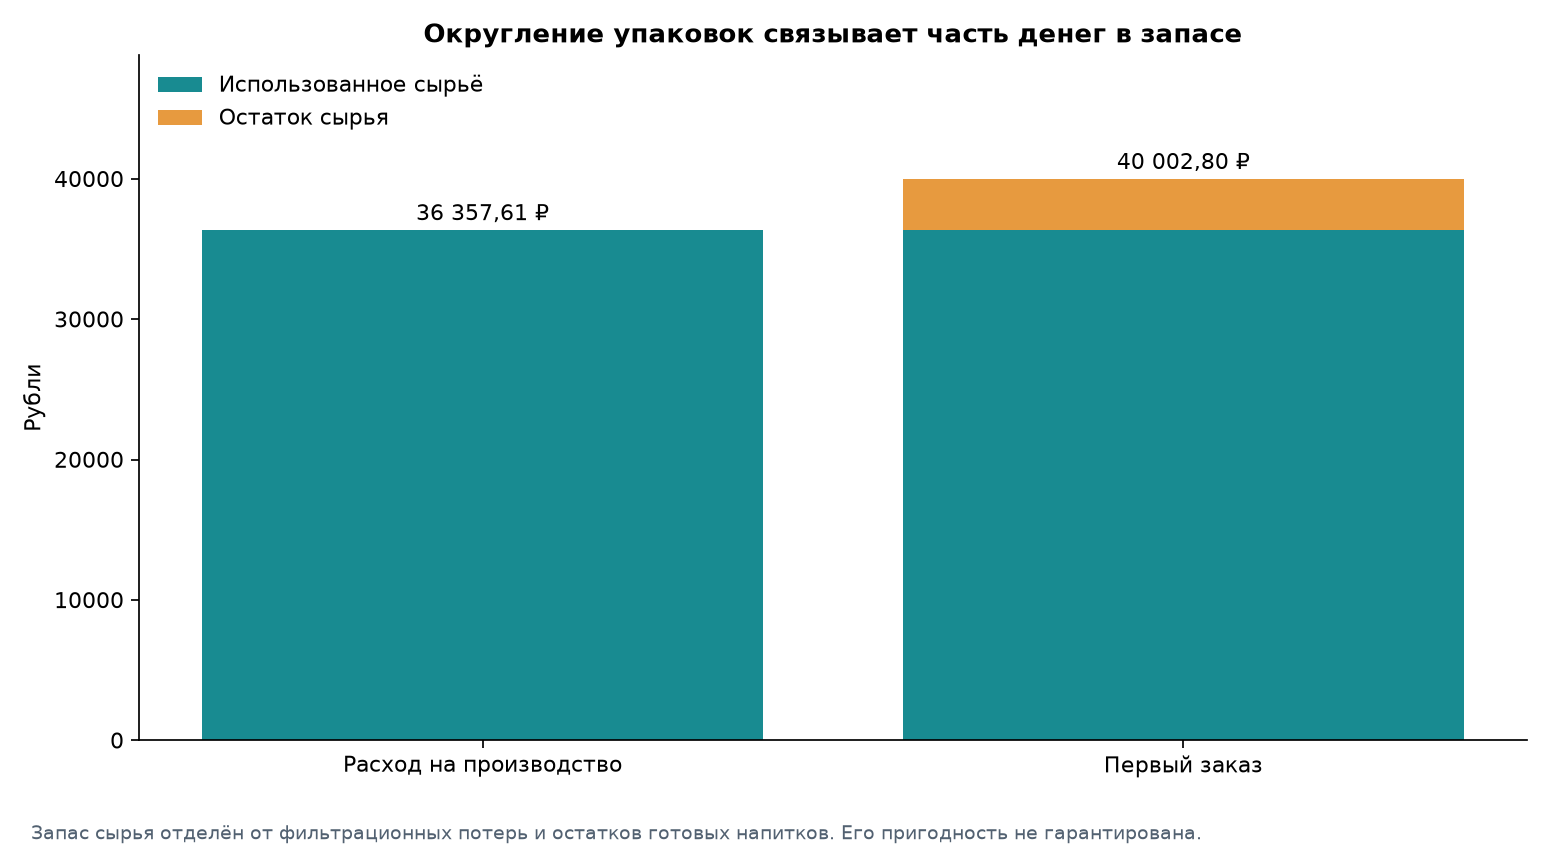

In [5]:
basket = read("procurement.csv")
show(read("ingredient_matrix.csv"))
show(basket[["ingredient_id","needed_quantity","base_unit","recipes_using","packs_to_buy","purchased_quantity","purchase_cost_rub","used_cost_rub","leftover_quantity","leftover_value_rub","joint_rounding_saving_rub"]])
show(read("suppliers.csv"))
fig("supplier_budget.png")
fig("used_vs_purchased.png")

Доставка новых трёх поставщиков и минимумы не установлены; они не равны нулю и не включены в сырьевой бюджет. Авторская ставка водки 380 ₽/л сохранена. Хрен в публичной карточке имеет противоречивый состав с уксусом и солью — нужен именно необработанный корень. Для METRO показаны лишь индексные ориентиры оптовых условий; текущая доступность и выбранный магазин требуют подтверждения.

## 5. Себестоимость и потенциальная выручка

Базовый план 60 л соответствует 1200 порциям. Все суммы вычислены Decimal без промежуточного округления. Материальная маржинальность не включает труд, аренду, налоги, оборудование, доставку и списания, поэтому не является чистой прибылью.

candidate_id,normalized_flavor,source_batch_cost_rub,planned_yield_ml,scale_factor,used_cost_rub,cost_50ml_rub,price_50ml_rub,material_margin_50ml_rub,material_margin_fraction,potential_revenue_rub,potential_material_contribution_rub
C01,Хреновуха,"260,28",470,"12,765957","3 322,66","27,69","250,00","222,31","88,92%","30 000,00","26 677,34"
C02,Вишня,"407,98",690,"8,695652","3 547,61","29,56","250,00","220,44","88,17%","30 000,00","26 452,39"
C03,Малина,"504,28",680,"8,823529","4 449,53","37,08","250,00","212,92","85,17%","30 000,00","25 550,47"
C04,Лимончелло,"756,55",1 500,"4,000000","3 026,20","25,22","250,00","224,78","89,91%","30 000,00","26 973,80"
C05,Щавель,"361,90",530,"11,320755","4 096,98","34,14","250,00","215,86","86,34%","30 000,00","25 903,02"
C09,Яблоко — базилик,"276,76",650,"9,230769","2 554,68","21,29","250,00","228,71","91,48%","30 000,00","27 445,32"
C13,Облепиха,"396,79",720,"8,333333","3 306,58","27,55","250,00","222,45","88,98%","30 000,00","26 693,42"
C14,Клюква,"408,54",670,"8,955224","3 658,52","30,49","250,00","219,51","87,80%","30 000,00","26 341,48"
C06,Халва,"332,17",450,"13,333333","4 428,93","36,91","300,00","263,09","87,70%","36 000,00","31 571,07"
C12,Малина — сливки,"462,69",700,"8,571429","3 965,91","33,05","300,00","266,95","88,98%","36 000,00","32 034,09"


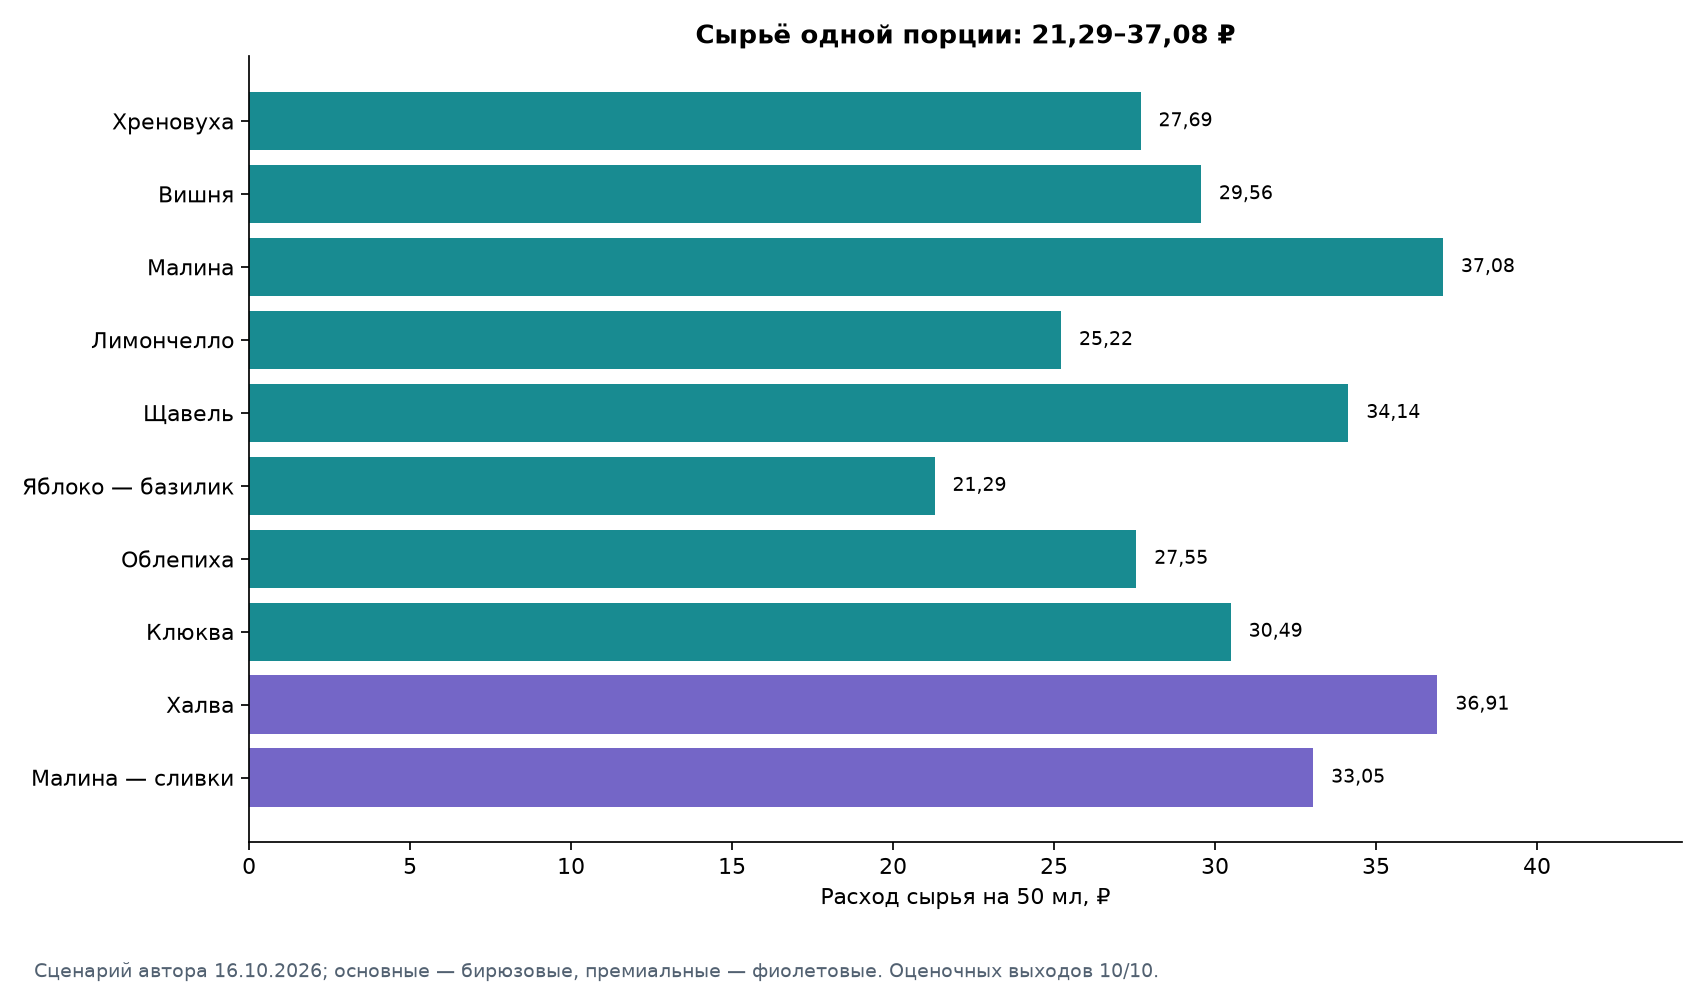

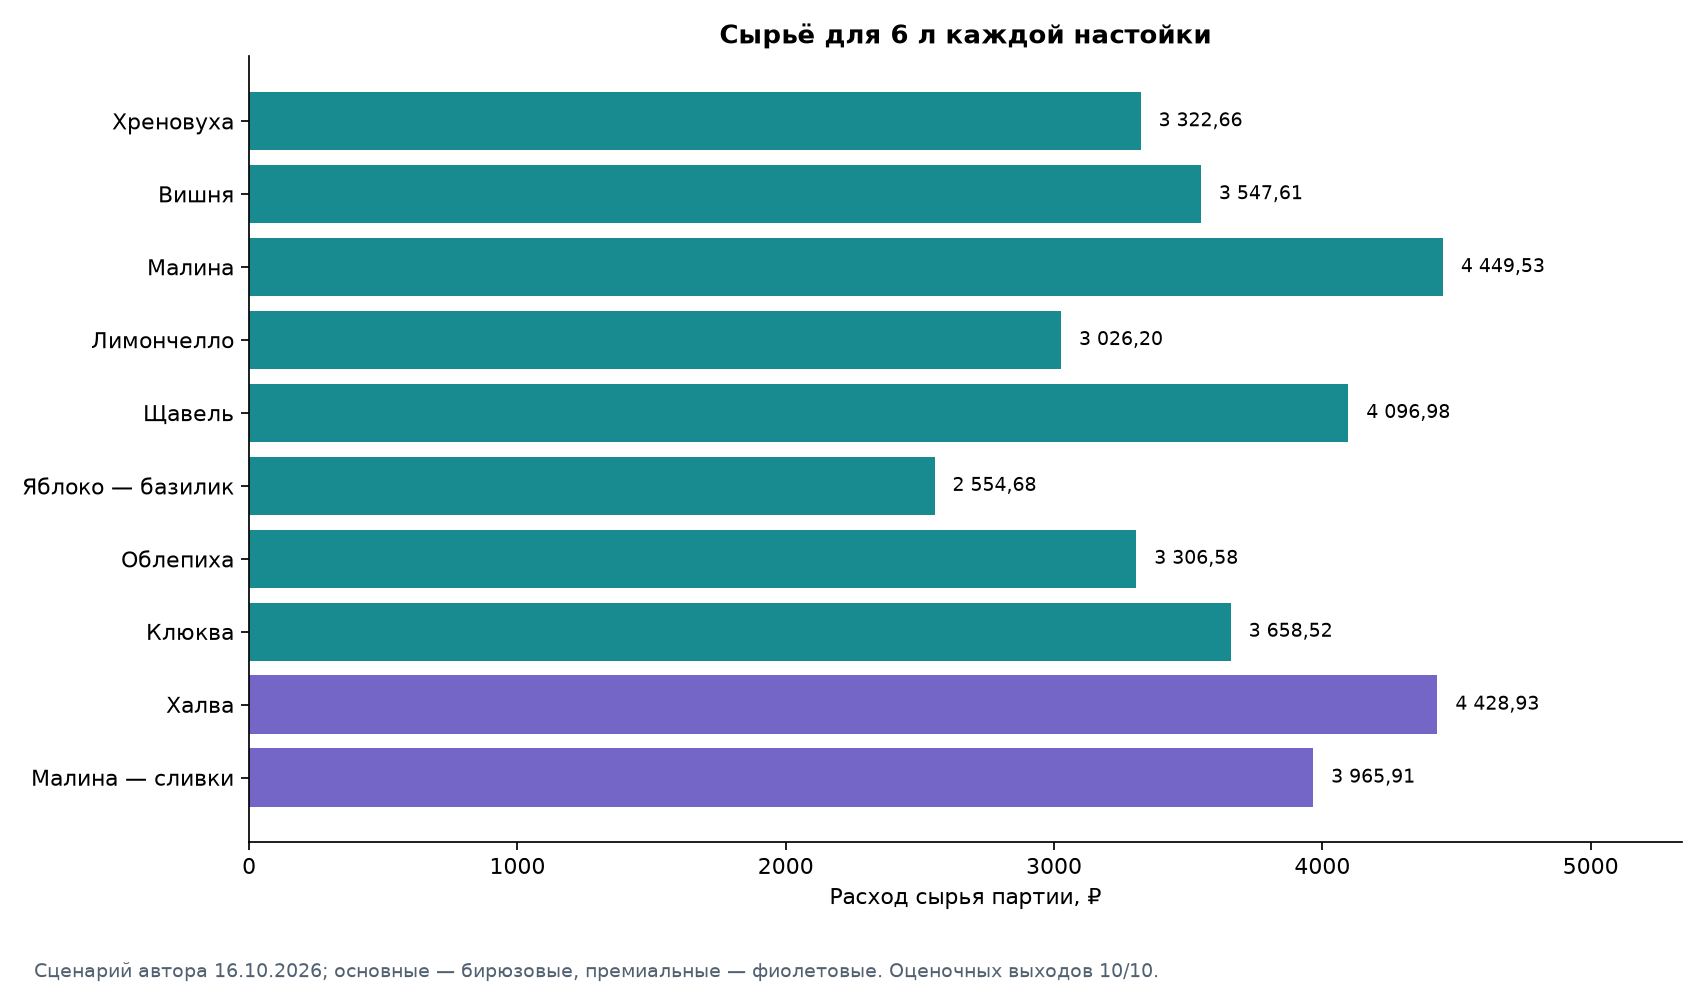

Агрегат до округления: 36357.61
Сумма показанных округлённых строк: 36357.60


In [6]:
costs = read("recipe_costs.csv")
show(costs[["candidate_id","normalized_flavor","source_batch_cost_rub","planned_yield_ml","scale_factor","used_cost_rub","cost_50ml_rub","price_50ml_rub","material_margin_50ml_rub","material_margin_fraction","potential_revenue_rub","potential_material_contribution_rub"]])
fig("cost_50ml.png")
fig("cost_6l.png")
print("Агрегат до округления:", e.money(result["used_cost_rub"]))
print("Сумма показанных округлённых строк:", e.money(result["displayed_item_costs_sum_rub"]))

Контрольный бюджет 40 002,80 ₽ и разбивка по поставщикам сходятся точно. Сумма округлённых строк сырья 36 357,60 ₽; сумма до округления даёт 36 357,61 ₽. Поэтому вклад после сырья 275 642,39 ₽ и остаток 3 645,19 ₽ отличаются от авторских ориентиров на копейку. Формулы не подгонялись.

## 6. Частичная реализация

Во всех сценариях уже произведены все 60 л. Выросшая доля непроданного не уменьшает потраченные ингредиенты. Выручка только от проданных порций; стоимость сырья проданного, всех произведённых порций и остаток готовой продукции разделены.

sell_through,produced_portions,sold_portions,unsold_portions,unsold_ready_ml,realized_revenue_rub,all_production_material_rub,sold_portions_material_rub,unsold_finished_material_value_rub,contribution_after_sold_material_rub,revenue_minus_all_production_material_rub,cash_after_ingredient_purchase_rub,financial_status,missing_price_ingredients,sales_status
"50,00%",1 200,600,600,30 000,"156 000,00","36 357,61","18 178,81","18 178,81","137 821,19","119 642,39","115 997,20",complete_price_scenario,недоступно,assumed_uniform_by_flavor
"70,00%",1 200,840,360,18 000,"218 400,00","36 357,61","25 450,33","10 907,28","192 949,67","182 042,39","178 397,20",complete_price_scenario,недоступно,assumed_uniform_by_flavor
"90,00%",1 200,1 080,120,6 000,"280 800,00","36 357,61","32 721,85","3 635,76","248 078,15","244 442,39","240 797,20",complete_price_scenario,недоступно,assumed_uniform_by_flavor
"100,00%",1 200,1 200,0,0,"312 000,00","36 357,61","36 357,61","0,00","275 642,39","275 642,39","271 997,20",complete_price_scenario,недоступно,assumed_uniform_by_flavor


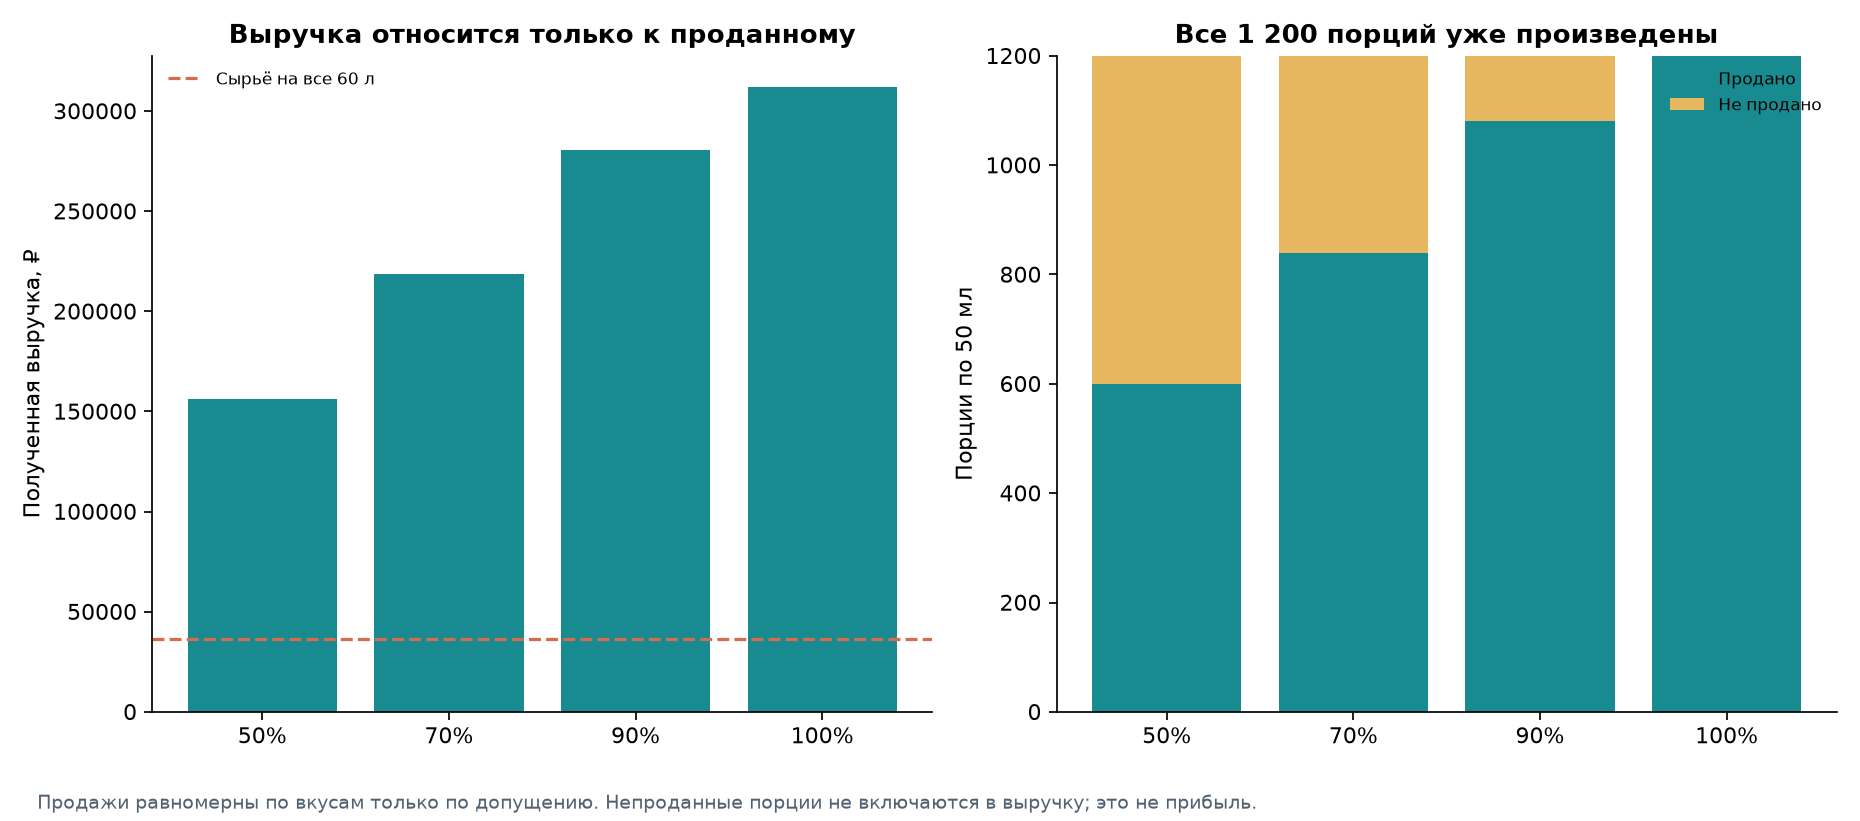

In [7]:
show(read("sales_scenarios.csv"))
fig("sell_through.png")

## 7. Доля премиальных продаж и предел запаса

При 5/20/35% средние цены 252,50/260/267,50 ₽. Доли вкусов внутри уровня равны по допущению. Премиальных порций всего 240, поэтому 35% не совместимы с реализацией всех 1200 порций. Невыполнимые сочетания помечены и не получают выручку от отсутствующих порций.

In [8]:
mix = read("premium_mix.csv")
show(mix)
assert mix.loc[~mix.stock_feasible,"realized_revenue_if_feasible_rub"].isna().all()

premium_share,requested_total_sell_through,weighted_price_rub,weighted_material_cost_rub,material_margin_fraction,requested_sold_portions,max_feasible_total_portions,stock_feasible,realized_revenue_if_feasible_rub,financial_status,missing_price_ingredients,sales_status
"5,00%","50,00%","252,50","29,42","88,35%",600,"1 010,526",да,"151 500,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"5,00%","70,00%","252,50","29,42","88,35%",840,"1 010,526",да,"212 100,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"5,00%","90,00%","252,50","29,42","88,35%",1 080,"1 010,526",нет,недоступно,complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"5,00%","100,00%","252,50","29,42","88,35%",1 200,"1 010,526",нет,недоступно,complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"20,00%","50,00%","260,00","30,30","88,35%",600,1 200,да,"156 000,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"20,00%","70,00%","260,00","30,30","88,35%",840,1 200,да,"218 400,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"20,00%","90,00%","260,00","30,30","88,35%",1 080,1 200,да,"280 800,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"20,00%","100,00%","260,00","30,30","88,35%",1 200,1 200,да,"312 000,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"35,00%","50,00%","267,50","31,18","88,35%",600,"685,714",да,"160 500,00",complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier
"35,00%","70,00%","267,50","31,18","88,35%",840,"685,714",нет,недоступно,complete_price_scenario,недоступно,scenario_not_observed_equal_within_tier


## 8. Цены, выходы и округление упаковок

Изменение цен не является новой договорной котировкой. Изменение выхода сохраняет готовую цель 6000 мл каждого вкуса, пересчитывая расход и упаковки. Тариф проверяется после округления упаковок: ниже порога нужна обычная цена с источником и датой. Без неё затронутые финансовые значения пусты, а итог меню недоступен. В сценарии +10% выхода для вишни нужны две упаковки при пороге три; подтверждённой обычной цены нет. Дополнительная упаковка ради скидки не покупается. Измеренный выход вводится только в yields.csv, без правки кода.

In [9]:
show(read("price_sensitivity.csv").loc[lambda x: x.candidate_id.eq("ALL")])
show(read("yield_sensitivity.csv").loc[lambda x: x.candidate_id.eq("ALL")])
show(basket[["ingredient_id","packs_to_buy","separate_recipe_packs","joint_rounding_saving_rub"]])

price_change,candidate_id,cost_50ml_rub,used_cost_rub,material_margin_fraction,financial_status,missing_price_ingredients,purchase_cost_rub
"-10,00%",ALL,"27,27","32 721,85","89,51%",complete_price_scenario,недоступно,"36 002,52"
"0,00%",ALL,"30,30","36 357,61","88,35%",complete_price_scenario,недоступно,"40 002,80"
"10,00%",ALL,"33,33","39 993,37","87,18%",complete_price_scenario,недоступно,"44 003,08"
"20,00%",ALL,"36,36","43 629,13","86,02%",complete_price_scenario,недоступно,"48 003,36"


yield_multiplier,candidate_id,changed_yield_ml,target_ready_ml,cost_50ml_rub,used_cost_rub,financial_status,missing_price_ingredients,purchase_cost_rub,material_margin_fraction,indexed_rate_thresholds_met,unmet_indexed_threshold_ingredients,unmet_threshold_pack_counts
"0,80",ALL,недоступно,60 000,недоступно,"45 447,02",complete_price_scenario,недоступно,"48 464,70","85,43%",да,недоступно,недоступно
"0,90",ALL,недоступно,60 000,недоступно,"40 397,35",complete_price_scenario,недоступно,"42 699,30","87,05%",да,недоступно,недоступно
"1,00",ALL,недоступно,60 000,недоступно,"36 357,61",complete_price_scenario,недоступно,"40 002,80","88,35%",да,недоступно,недоступно
"1,10",ALL,недоступно,60 000,недоступно,недоступно,incomplete_missing_price,cherry,недоступно,недоступно,нет,cherry,cherry:2


ingredient_id,packs_to_buy,separate_recipe_packs,joint_rounding_saving_rub
vodka,48,52,"1 520,00"
cherry,3,3,"0,00"
raspberry,6,6,"0,00"
sea_buckthorn,5,5,"0,00"
cranberry,4,4,"0,00"
lemon,8,8,"0,00"
sorrel,12,12,"0,00"
basil,3,3,"0,00"
sugar,10,12,"145,80"
honey,3,5,"658,00"


## 9. Что нужно подтвердить

Поставка водки по авторской ставке, акции/торговый центр METRO, свежий необработанный хрен, единицы заказа Агропарка, доставка и минимумы остаются предметом согласования. Нужны надлежащие условия хранения молочного варианта и проверка требований пищевой безопасности. Измеренные выходы следует внести после производства. Новые рецептурные эксперименты в этот этап не включены.

60 порций каждого вкуса за вечер — план автора, а не доказанный спрос. Упаковочные остатки и непроданные напитки — разные риски. Высокая сырьевая маржинальность не устанавливает полную прибыльность бара. Состав сохранён; PR остаётся Draft, main не изменяется без отдельного разрешения.

In [10]:
assert e.check_baseline()
manifest = json.loads((out/"run_manifest.json").read_text())
for name,digest in manifest["inputs_sha256"].items():
    assert hashlib.sha256((ROOT/"data/economics"/name).read_bytes()).hexdigest() == digest
assert result["total_ready_ml"] == 60000 and result["total_portions"] == 1200
assert e.money(result["purchase_cost_rub"]) == e.money(sum(e.D(str(x)) for x in read("procurement.csv").purchase_cost_rub))
assert not result["optimizer_called"]
print("Текущая модель, 60 л, 1200 порций и защищённая база проверены. Тесты запускаются отдельно свежим pytest.")

Текущая модель, 60 л, 1200 порций и защищённая база проверены. Тесты запускаются отдельно свежим pytest.
